# Proyecto Parcial 2: Procesamiento Digital de Señales
## Diseño interactivo de filtros digitales en el plano Z

### Fundamento Teórico
El diseño de filtros digitales mediante el **plano Z** permite construir y analizar sistemas Lineales Invariantes en el Tiempo (LTI) manipulando gráficamente su función de transferencia $H(z)$. Esta función está determinada por sus raíces:

* **Ceros (O):** Valores que anulan el numerador de $H(z)$. En estas posiciones, la ganancia del sistema cae a cero. Se usan para atenuar o bloquear frecuencias específicas.
* **Polos (X):** Valores que anulan el denominador de $H(z)$. En estas posiciones, la ganancia tiende a infinito, lo que introduce resonancia o amplificación en las frecuencias cercanas.

**Conceptos clave para el diseño experimental:**
1. **Respuesta en frecuencia:** Se evalúa recorriendo el **círculo unitario** ($z = e^{j\omega}$). La distancia geométrica desde un punto del círculo hacia los ceros reduce la magnitud de la señal, mientras que la cercanía a los polos la incrementa.
2. **Estabilidad:** Para que un filtro causal sea estable, **todos sus polos** deben ubicarse estrictamente **dentro del círculo unitario** ($|z| < 1$). Los ceros pueden estar en cualquier parte.
3. **Respuesta al impulso ($h[n]$):** Muestra el comportamiento del sistema en el dominio del tiempo ante una señal de impulso. Refleja la rapidez de respuesta y, en el caso de polos cercanos al borde del círculo, muestra oscilaciones prolongadas.

# Configuración del entorno
Instalación de la biblioteca `ipympl` y activación del manejador de widgets para habilitar la interactividad de las gráficas.

In [ ]:
!pip install ipympl
from google.colab import output
output.enable_custom_widget_manager()
%matplotlib widget

# Herramienta interactiva: Diseño en el Plano Z
Simulador para construir la función de transferencia $H(z)$ y visualizar su respuesta.
* **Clic izquierdo:** Agrega un cero.
* **Clic derecho:** Agrega un polo.
* **Tecla "d":** Posiciona el cursor sobre una raíz y presiona la tecla para eliminarla.

<>:90: SyntaxWarning: invalid escape sequence '\o'
<>:108: SyntaxWarning: invalid escape sequence '\o'
<>:115: SyntaxWarning: invalid escape sequence '\o'
<>:90: SyntaxWarning: invalid escape sequence '\o'
<>:108: SyntaxWarning: invalid escape sequence '\o'
<>:115: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_6912/1302806257.py:90: SyntaxWarning: invalid escape sequence '\o'
  self.ax_z.plot(z_point.real, z_point.imag, 'go', label=f'$e^{{j\omega}}$')
/tmp/ipykernel_6912/1302806257.py:108: SyntaxWarning: invalid escape sequence '\o'
  self.ax_mag.set_title('Magnitud $|H(e^{j\omega})|$')
/tmp/ipykernel_6912/1302806257.py:115: SyntaxWarning: invalid escape sequence '\o'
  self.ax_phase.set_title('Fase $\\angle H(e^{j\omega})$')


FloatSlider(value=0.7853981633974483, description='ω (rad):', max=3.141592653589793, step=0.05)

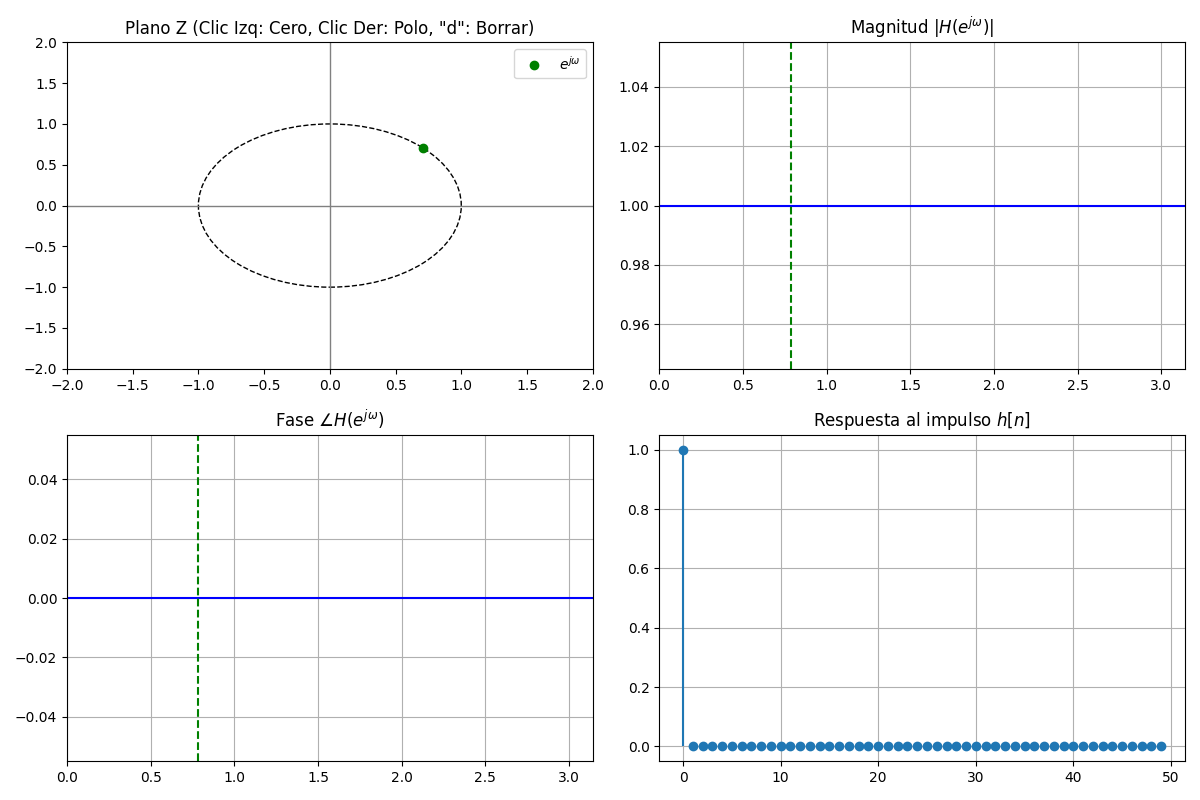

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
import ipywidgets as widgets
from IPython.display import display

class ZPlaneFilterDesigner:
    def __init__(self):
        self.zeros = []
        self.poles = []
        self.k = 1.0

        # Configuración de la figura
        self.fig = plt.figure(figsize=(12, 8))
        self.ax_z = self.fig.add_subplot(221)
        self.ax_mag = self.fig.add_subplot(222)
        self.ax_phase = self.fig.add_subplot(223)
        self.ax_imp = self.fig.add_subplot(224)

        # Slider para exploración geométrica (w)
        self.w_slider = widgets.FloatSlider(value=np.pi/4, min=0, max=np.pi, step=0.05, description='ω (rad):')
        self.w_slider.observe(self.update_plots, names='value')
        display(self.w_slider)

        # Eventos del ratón y teclado
        self.fig.canvas.mpl_connect('button_press_event', self.on_click)
        self.fig.canvas.mpl_connect('key_press_event', self.on_key)

        self.update_plots()

    def add_root(self, x, y, is_pole):
        root = complex(x, y)
        target_list = self.poles if is_pole else self.zeros
        target_list.append(root)
        if abs(y) > 0.01: # Agregar conjugado si es complejo
            target_list.append(complex(x, -y))
        self.update_plots()

    def remove_root(self, x, y):
        clicked = complex(x, y)
        for lst in (self.zeros, self.poles):
            if not lst: continue
            # Encontrar la raíz más cercana
            dists = [abs(r - clicked) for r in lst]
            idx = np.argmin(dists)
            if dists[idx] < 0.1:
                root_to_remove = lst.pop(idx)
                # Eliminar también el conjugado si existe
                if abs(root_to_remove.imag) > 0.01:
                    conj_dists = [abs(r - np.conj(root_to_remove)) for r in lst]
                    if conj_dists:
                        conj_idx = np.argmin(conj_dists)
                        if conj_dists[conj_idx] < 0.1:
                            lst.pop(conj_idx)
                break
        self.update_plots()

    def on_click(self, event):
        if event.inaxes != self.ax_z: return
        if event.button == 1: # Clic izquierdo: Cero
            self.add_root(event.xdata, event.ydata, is_pole=False)
        elif event.button == 3: # Clic derecho: Polo
            self.add_root(event.xdata, event.ydata, is_pole=True)

    def on_key(self, event):
        if event.inaxes != self.ax_z or event.key != 'd': return
        self.remove_root(event.xdata, event.ydata)

    def update_plots(self, change=None):
        w_val = self.w_slider.value
        z_point = np.exp(1j * w_val)

        # 1. Plano Z
        self.ax_z.clear()
        circle = plt.Circle((0, 0), 1, color='black', fill=False, linestyle='--')
        self.ax_z.add_patch(circle)
        self.ax_z.axhline(0, color='gray', lw=1)
        self.ax_z.axvline(0, color='gray', lw=1)

        if self.zeros:
            z_real = [z.real for z in self.zeros]
            z_imag = [z.imag for z in self.zeros]
            self.ax_z.scatter(z_real, z_imag, s=80, marker='o', facecolors='none', edgecolors='b', label='Ceros')
        if self.poles:
            p_real = [p.real for p in self.poles]
            p_imag = [p.imag for p in self.poles]
            self.ax_z.scatter(p_real, p_imag, s=80, marker='x', color='r', label='Polos')

        # Exploración geométrica en Plano Z
        self.ax_z.plot(z_point.real, z_point.imag, 'go', label=f'$e^{{j\omega}}$')
        for z in self.zeros: self.ax_z.plot([z_point.real, z.real], [z_point.imag, z.imag], 'b:', alpha=0.5)
        for p in self.poles: self.ax_z.plot([z_point.real, p.real], [z_point.imag, p.imag], 'r:', alpha=0.5)

        self.ax_z.set_xlim([-2, 2])
        self.ax_z.set_ylim([-2, 2])
        self.ax_z.set_title('Plano Z (Clic Izq: Cero, Clic Der: Polo, "d": Borrar)')
        self.ax_z.legend(loc='upper right')

        # Obtener coeficientes de H(z)
        b, a = sig.zpk2tf(self.zeros, self.poles, self.k)

        # 2 y 3. Respuesta en Frecuencia (Magnitud y Fase)
        w, h = sig.freqz(b, a, worN=512, whole=False)

        self.ax_mag.clear()
        self.ax_mag.plot(w, np.abs(h), 'b')
        self.ax_mag.axvline(w_val, color='g', linestyle='--')
        self.ax_mag.set_title('Magnitud $|H(e^{j\omega})|$')
        self.ax_mag.set_xlim([0, np.pi])
        self.ax_mag.grid(True)

        self.ax_phase.clear()
        self.ax_phase.plot(w, np.angle(h), 'b')
        self.ax_phase.axvline(w_val, color='g', linestyle='--')
        self.ax_phase.set_title('Fase $\\angle H(e^{j\omega})$')
        self.ax_phase.set_xlim([0, np.pi])
        self.ax_phase.grid(True)

        # 4. Respuesta al Impulso
        self.ax_imp.clear()
        n = np.arange(50)
        impulse = np.zeros(50)
        impulse[0] = 1
        h_n = sig.lfilter(b, a, impulse)
        self.ax_imp.stem(n, h_n, basefmt=" ")
        self.ax_imp.set_title('Respuesta al impulso $h[n]$')
        self.ax_imp.grid(True)

        self.fig.tight_layout()
        self.fig.canvas.draw_idle()

# Iniciar la aplicación
app = ZPlaneFilterDesigner()

# Extracción de coeficientes $H(z)$
Ejecuta la celda de abajo tras finalizar cada diseño en el simulador. Extrae los valores numéricos del numerador y denominador para documentar el modelo matemático del filtro.

In [ ]:
import scipy.signal as sig
import numpy as np

# Calcular la función de transferencia con el estado actual de la interfaz
b, a = sig.zpk2tf(app.zeros, app.poles, app.k)

print("Coeficientes de la Función de Transferencia H(z)")
print("=" * 50)
print(f"Numerador (b):   {np.round(b, 4)}")
print(f"Denominador (a): {np.round(a, 4)}")

print("\nUbicación de las raíces")
print("=" * 50)
print(f"Ceros: {np.round(app.zeros, 4) if app.zeros else 'Ninguno'}")
print(f"Polos: {np.round(app.poles, 4) if app.poles else 'Ninguno'}")

Coeficientes de la Función de Transferencia H(z)
Numerador (b):   [1.     1.9923 0.9927]
Denominador (a): [ 1.     -1.8164  0.825 ]

Ubicación de las raíces
Ceros: [-0.9962+0.0178j -0.9962-0.0178j]
Polos: [0.9082+0.0143j 0.9082-0.0143j]


# Resultados y Experimentos

### 1. Filtro Pasa-bajas
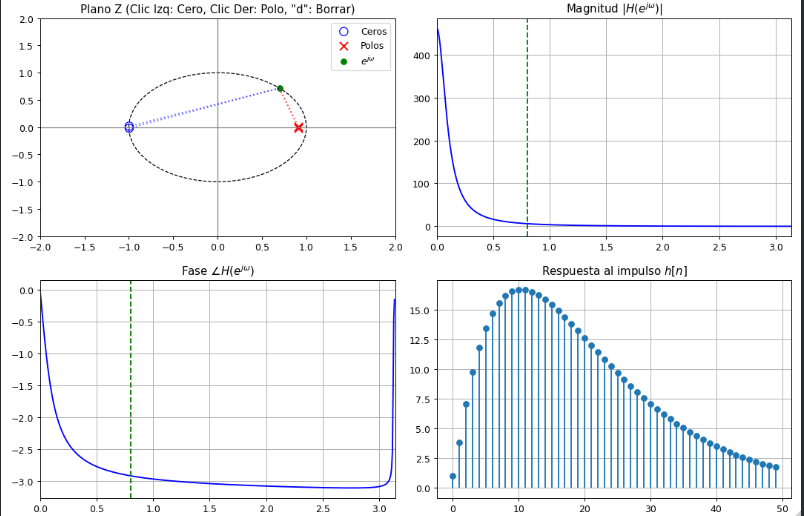

**Explicación:** Los polos se ubicaron en la región de baja frecuencia (cerca de $z=1$) y los ceros en alta frecuencia ($z=-1$), logrando atenuar las componentes de alta variación. El sistema es estable dado que los polos están estrictamente dentro del círculo unitario.

### 2. Filtro Pasa-altas
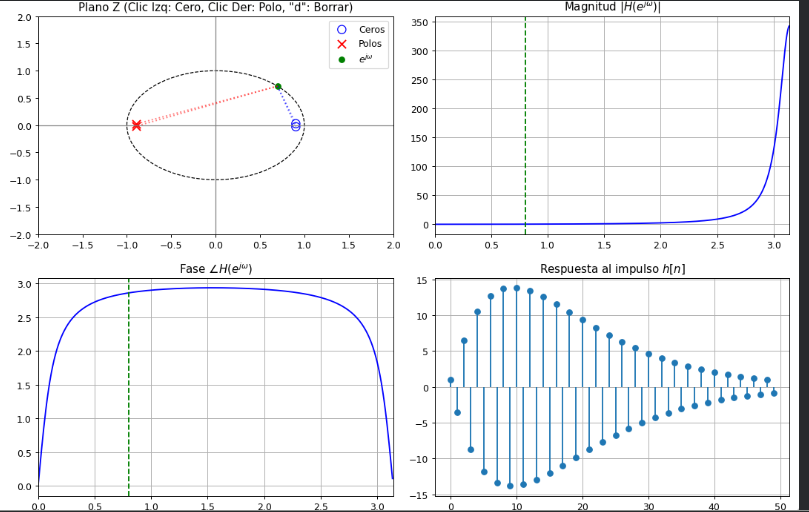

**Explicación:** La configuración se invirtió colocando ceros en $z=1$ para bloquear la componente de corriente continua (DC) y polos cerca de $z=-1$, permitiendo el paso de frecuencias altas.

### 3. Filtro Notch
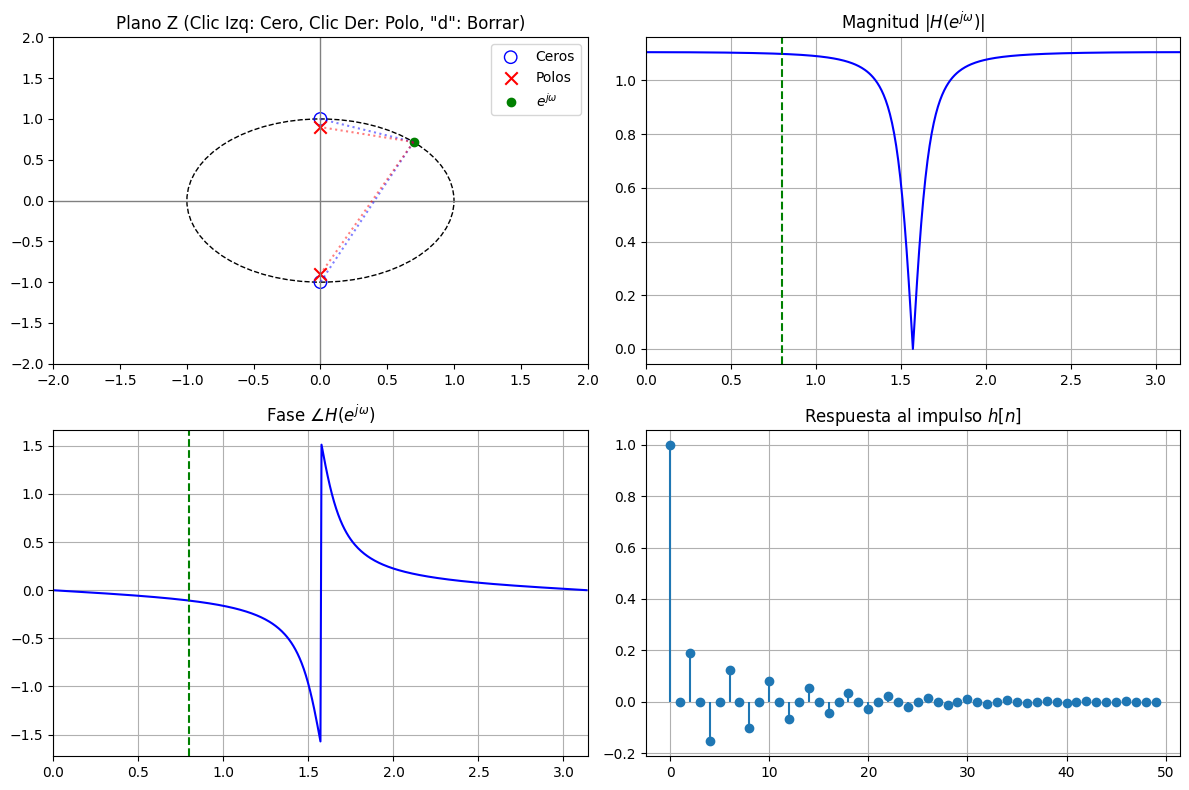

**Explicación:** Se insertó un par de ceros conjugados directamente sobre el círculo unitario en la frecuencia objetivo para forzar una atenuación total (rechazo). Se añadieron polos justo detrás de los ceros para aplanar y recuperar rápidamente la ganancia en las bandas laterales.

### 4. Análisis de Resonancia
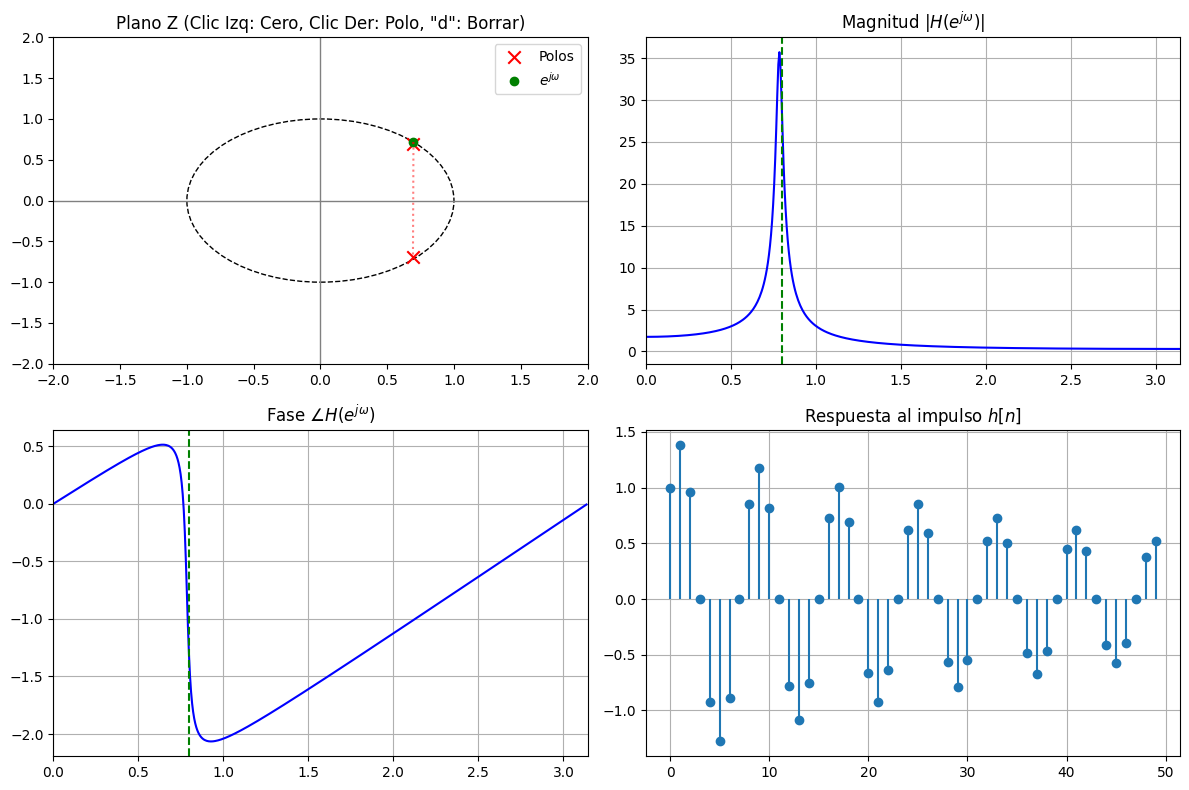

**Explicación:** Se aumentó progresivamente el radio de un par de polos conjugados hacia el límite del círculo unitario ($|z| \to 1$). Esto amplificó drásticamente el pico de magnitud en esa frecuencia específica y prolongó la duración de las oscilaciones en la respuesta al impulso, llevando al sistema al límite de la estabilidad.